Проверить оборудование

In [1]:
import os
import sys
import subprocess
from pathlib import Path

# Все последующие процессы будут видеть только первую GPU.
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["HF_HOME"] = "/tmp/lab1-hf"


def cmd(arguments, cwd=None, show=True):
    result = subprocess.run(
        arguments,
        cwd=cwd,
        capture_output=True,
        text=True,
    )
    if show or result.returncode != 0:
        print(result.stdout)
        if result.stderr:
            print(result.stderr)
    result.check_returncode()
    return result


print("Python блокнота:", sys.version)
cmd(["nvidia-smi"])

gpu_name = cmd([
    "nvidia-smi",
    "--id=0",
    "--query-gpu=name",
    "--format=csv,noheader",
]).stdout.strip()

assert "T4" in gpu_name, f"Ожидали T4, получено: {gpu_name}"
print("Используем:", gpu_name)

Python блокнота: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Wed Nov  4 09:30:26 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |    

Загрузить зафиксированный код

In [2]:
import re

COMMIT = "bcaf093047b54b91aef7df2ae37d9e5d8182e8bb"
assert re.fullmatch(r"[0-9a-f]{40}", COMMIT), "Нужно вставить полный хеш коммита"

REPO = Path("/tmp/intsys-labs")

if not REPO.exists():
    cmd([
        "git", "clone",
        "https://github.com/manaer6-alt/intsys-labs.git",
        str(REPO),
    ])

# Не перезаписываем случайные изменения в существующей копии.
assert not cmd(
    ["git", "status", "--porcelain"], cwd=REPO
).stdout.strip(), "В копии репозитория есть изменения"

cmd(["git", "fetch", "origin"], cwd=REPO)
cmd(["git", "checkout", "--detach", COMMIT], cwd=REPO)

actual_commit = cmd(
    ["git", "rev-parse", "HEAD"], cwd=REPO
).stdout.strip()

assert actual_commit == COMMIT
print("Загружена нужная версия кода.")




HEAD is now at bcaf093 Prepare reproducible lab1 experiments for Kaggle single T4

bcaf093047b54b91aef7df2ae37d9e5d8182e8bb

Загружена нужная версия кода.


Установить окружение

In [3]:
%pip install -q uv

Note: you may need to restart the kernel to use updated packages.


In [4]:
import json

ART = Path("/kaggle/working/lab1_artifacts")
ART.mkdir(parents=True, exist_ok=True)

PYTHON = "/tmp/lab1-env/bin/python"

config = json.loads(
    (REPO / "configs/lab1_kaggle.json").read_text(encoding="utf-8")
)
assert config["revision"], "Ревизия модели не зафиксирована"

if not Path(PYTHON).exists():
    cmd([
        "uv", "venv",
        "--python", "3.13",
        "--seed",
        "/tmp/lab1-env",
    ])

cmd([
    "uv", "pip", "install",
    "--python", PYTHON,
    f"vllm=={config['vllm_version']}",
    "openai", "mlflow", "matplotlib",
    "--torch-backend=auto",
])

# Сохраняем реально установленные версии.
freeze = cmd([
    "uv", "pip", "freeze",
    "--python", PYTHON,
], show=False)

(ART / "requirements_kaggle.txt").write_text(
    freeze.stdout, encoding="utf-8"
)

# Проверяем не только обнаружение GPU, но и выполнение CUDA-операции.
check_code = """
import torch
from importlib.metadata import version

print("vLLM:", version("vllm"))
print("PyTorch:", torch.__version__)
print("CUDA в PyTorch:", torch.version.cuda)
print("Видимых GPU:", torch.cuda.device_count())

assert torch.cuda.is_available(), "CUDA недоступна"
assert torch.cuda.device_count() == 1, "Процесс должен видеть одну GPU"

print("GPU:", torch.cuda.get_device_name(0))
print("Проверочный тензор:", torch.ones(1, device="cuda").cpu())
"""

cmd([PYTHON, "-c", check_code])


Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment with seed packages at: /tmp/lab1-env
 + pip==26.3
Activate with: source /tmp/lab1-env/bin/activate


Using Python 3.13.16 environment at: /tmp/lab1-env
Resolved 243 packages in 2.49s
Prepared 243 packages in 2m 23s
Installed 243 packages in 698ms
 + agent-detector==2.0.0
 + aiohappyeyeballs==2.7.1
 + aiohttp==3.14.5
 + aiosignal==1.4.0
 + alembic==1.20.1
 + annotated-doc==0.0.5
 + annotated-types==0.8.0
 + anthropic==2.4.0
 + anyio==4.16.0
 + apache-tvm-ffi==0.1.11
 + astor==0.8.1
 + attrs==26.1.0
 + blake3==1.0.11
 + blinker==1.9.0
 + cachetools==7.2.8
 + cbor2==6.2.0.post2
 + certifi==2026.10.23
 + cffi==2.1.1
 + charset-normalizer==3.5.2
 + click==8.5.0
 + cloudpickle==3.1.2
 + compressed-tensors==0.17.0
 + contourpy==1.4.0
 + cryptography==50.0.2
 + cuda-bindings==13.4.4
 + cuda-core==1.2.2
 + cuda-pathfinder==1.8.5
 + cuda-python==13.4.4
 + cuda-tile==1.7.0
 + cuda-toolkit==13.2.1
 + cycler==0.12.

CompletedProcess(args=['/tmp/lab1-env/bin/python', '-c', '\nimport torch\nfrom importlib.metadata import version\n\nprint("vLLM:", version("vllm"))\nprint("PyTorch:", torch.__version__)\nprint("CUDA в PyTorch:", torch.version.cuda)\nprint("Видимых GPU:", torch.cuda.device_count())\n\nassert torch.cuda.is_available(), "CUDA недоступна"\nassert torch.cuda.device_count() == 1, "Процесс должен видеть одну GPU"\n\nprint("GPU:", torch.cuda.get_device_name(0))\nprint("Проверочный тензор:", torch.ones(1, device="cuda").cpu())\n'], returncode=0, stdout='vLLM: 0.33.0\nPyTorch: 2.14.0+cu132\nCUDA в PyTorch: 13.2\nВидимых GPU: 1\nGPU: Tesla T4\nПроверочный тензор: tensor([1.])\n', stderr="Error in sitecustomize; set PYTHONVERBOSE for traceback:\nModuleNotFoundError: No module named 'wrapt'\n")

Установим недостающий пакет и обновим список зависимостей.

In [5]:
# Добавляем недостающую библиотеку в наше окружение.
_ = cmd([
    "uv", "pip", "install",
    "--python", PYTHON,
    "wrapt",
])

# Проверяем, что сообщение об отсутствующем модуле исчезло.
_ = cmd([
    PYTHON, "-c",
    "import wrapt; print('Окружение запускается, wrapt доступен')",
])

# Обновляем сохранённый список фактически установленных библиотек.
freeze = cmd([
    "uv", "pip", "freeze",
    "--python", PYTHON,
], show=False)

(ART / "requirements_kaggle.txt").write_text(
    freeze.stdout, encoding="utf-8"
)
print("Список зависимостей обновлён.")


Using Python 3.13.16 environment at: /tmp/lab1-env
Resolved 1 package in 280ms
Prepared 1 package in 47ms
Installed 1 package in 1ms
 + wrapt==2.5.2

Окружение запускается, wrapt доступен

Список зависимостей обновлён.


Kaggle: подключить функции управления

In [6]:
# Этот модуль управляет отдельными процессами нашего окружения.
sys.path.insert(0, str(REPO / "lab1"))

from kaggle_helpers import (
    start_server,
    stop_server,
    stage,
    checkpoint,
)

print("Функции управления подключены.")

Функции управления подключены.


Запустить сервер без кеширования

In [7]:
# False — кеширование префикса выключено.
start_server(prefix=False)

Процесс сервера остановлен. GPU-сессия Kaggle ещё активна.
Запускается сервер; журнал: /kaggle/working/lab1_artifacts/server_sessions/b92896fe033448b79b36771806d40702/server.log
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
index, name, memory.total [MiB], driver_version
0, Tesla T4, 15360 MiB, 580.178.04
1, Tesla T4, 15360 MiB, 580.178.04
СЕРВЕР ГОТОВ; кеширование префикса: False
(EngineCore pid=425) INFO 11-04 09:39:12 [utils.py:381] Using LBNHC KV cache layout.
(EngineCore pid=425) INFO 11-04 09:40:06 [gpu_worker.py:772] Available KV cache memory: 4.55 GiB
(EngineCore pid=425) INFO 11-04 09:40:06 [gpu_worker.py:787] CUDA graph memory p

Выполнить обязательные проверки

In [8]:
stage("check")

Каталог: /kaggle/working/lab1_artifacts/check/7008927a5aa3421e89732827e8105d11
{
  "arithmetic_ok": true,
  "output_64_ok": true,
  "texts_equal": true,
  "kv_bytes_per_token_fp16": 147456,
  "kv_bytes_for_8_users_4000_tokens": 4718592000,
  "server_kv_log_lines": [
    "(EngineCore pid=425) INFO 11-04 09:37:56 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with config: model='Qwen/Qwen3-4B-Instruct-2507', speculative_config=None, tokenizer='Qwen/Qwen3-4B-Instruct-2507', skip_tokenizer_init=False, tokenizer_mode=auto, revision=cdbee75f17c01a7cc42f958dc650907174af0554, tokenizer_revision=cdbee75f17c01a7cc42f958dc650907174af0554, trust_remote_code=False, dtype=torch.float16, max_seq_len=32768, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, aux_output_config=AuxOutputCo

Эксперимент 1 — длина запроса

In [9]:
# 25 последовательных запросов.
# Вход: 256, 1024, 4096, 8192, 16384 токена.
# По 5 повторов, ответ — ровно 16 токенов.
stage("exp1")

archive_exp1 = checkpoint("exp1")

Каталог: /kaggle/working/lab1_artifacts/exp1/59007888fc974d3788b08fe059a1e344
exp1 1/25 | вход 256 | выход 16 | TTFT 0.128 с | TPOT 35.93 мс
exp1 2/25 | вход 256 | выход 16 | TTFT 0.127 с | TPOT 35.97 мс
exp1 3/25 | вход 256 | выход 16 | TTFT 0.128 с | TPOT 35.99 мс
exp1 4/25 | вход 256 | выход 16 | TTFT 0.128 с | TPOT 35.99 мс
exp1 5/25 | вход 256 | выход 16 | TTFT 0.129 с | TPOT 35.95 мс
exp1 6/25 | вход 1024 | выход 16 | TTFT 0.756 с | TPOT 39.44 мс
exp1 7/25 | вход 1024 | выход 16 | TTFT 0.739 с | TPOT 39.57 мс
exp1 8/25 | вход 1024 | выход 16 | TTFT 0.739 с | TPOT 39.57 мс
exp1 9/25 | вход 1024 | выход 16 | TTFT 0.737 с | TPOT 39.55 мс
exp1 10/25 | вход 1024 | выход 16 | TTFT 0.741 с | TPOT 39.52 мс
exp1 11/25 | вход 4096 | выход 16 | TTFT 7.974 с | TPOT 50.74 мс
exp1 12/25 | вход 4096 | выход 16 | TTFT 8.022 с | TPOT 51.04 мс
exp1 13/25 | вход 4096 | выход 16 | TTFT 8.033 с | TPOT 51.23 мс
exp1 14/25 | вход 4096 | выход 16 | TTFT 8.120 с | TPOT 51.15 мс
exp1 15/25 | вход 4096 | в

Проверка кеширования префикса
Перезапускаем сервер с кешированием. Веса повторно скачивать не потребуется.

In [10]:
start_server(prefix=True)

Процесс сервера остановлен. GPU-сессия Kaggle ещё активна.
Запускается сервер; журнал: /kaggle/working/lab1_artifacts/server_sessions/9d65c4324c1240ca97b3d5b6990a69f9/server.log
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
index, name, memory.total [MiB], driver_version
0, Tesla T4, 15360 MiB, 580.178.04
1, Tesla T4, 15360 MiB, 580.178.04
СЕРВЕР ГОТОВ; кеширование префикса: True
(EngineCore pid=682) INFO 11-04 10:06:18 [utils.py:381] Using LBNHC KV cache layout.
(EngineCore pid=682) INFO 11-04 10:06:25 [gpu_worker.py:772] Available KV cache memory: 5.15 GiB
(EngineCore pid=682) INFO 11-04 10:06:25 [gpu_worker.py:787] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9000 is equivalent to --gpu-memory-utilization=0.8914 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase --gpu-memory-utilization to 0.9086. To di

In [11]:
# Другой короткий запрос для прогрева.
# Затем три полностью одинаковых запроса на 8192 токена.
stage("cache")

archive_cache = checkpoint("cache")

Каталог: /kaggle/working/lab1_artifacts/cache/9ea743be04024a6ab9f6b8814e4da96d
cache 1/3 | вход 8192 | выход 16 | TTFT 29.253 с | TPOT 67.75 мс
cache 2/3 | вход 8192 | выход 16 | TTFT 0.221 с | TPOT 67.66 мс
cache 3/3 | вход 8192 | выход 16 | TTFT 0.215 с | TPOT 67.76 мс
ЗАВЕРШЕНО: /kaggle/working/lab1_artifacts/cache/9ea743be04024a6ab9f6b8814e4da96d
АРХИВ: /kaggle/working/lab1_cache_655bf373.zip
SHA-256: dc1951cfb746f35bd0707399541721d958fabe5a2b1c7f3f974ab8cd5914ad07
Скачай его через панель файлов Kaggle перед завершением сессии.


Эксперимент 2 — длина ответа

In [12]:
start_server(prefix=False)

Процесс сервера остановлен. GPU-сессия Kaggle ещё активна.
Запускается сервер; журнал: /kaggle/working/lab1_artifacts/server_sessions/67e4f050630e4efdb83a0263db2bd881/server.log
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
Ожидание запуска...
index, name, memory.total [MiB], driver_version
0, Tesla T4, 15360 MiB, 580.178.04
1, Tesla T4, 15360 MiB, 580.178.04
СЕРВЕР ГОТОВ; кеширование префикса: False
(EngineCore pid=821) INFO 11-04 10:11:23 [utils.py:381] Using LBNHC KV cache layout.
(EngineCore pid=821) INFO 11-04 10:11:43 [gpu_worker.py:772] Available KV cache memory: 5.15 GiB
(EngineCore pid=821) INFO 11-04 10:11:43 [gpu_worker.py:787] CUDA graph memory profiling is enabled (default since v0.21.0). The current --gpu-memory-utilization=0.9000 is equivalent to --gpu-memory-utilization=0.8914 without CUDA graph memory profiling. To maintain the same effective KV cache size as before, increase 

In [13]:
# Вход — 1024 токена.
# Ответы — 16, 64, 256 и 1024 токена.
# По 5 повторов, всего 20 запросов.
stage("exp2")

archive_exp2 = checkpoint("exp2")

Каталог: /kaggle/working/lab1_artifacts/exp2/580254fb4e534eafbc2a0d5a0356e562
exp2 1/20 | вход 1024 | выход 16 | TTFT 0.747 с | TPOT 39.31 мс
exp2 2/20 | вход 1024 | выход 16 | TTFT 0.745 с | TPOT 39.35 мс
exp2 3/20 | вход 1024 | выход 16 | TTFT 0.742 с | TPOT 39.36 мс
exp2 4/20 | вход 1024 | выход 16 | TTFT 0.744 с | TPOT 39.36 мс
exp2 5/20 | вход 1024 | выход 16 | TTFT 0.743 с | TPOT 39.44 мс
exp2 6/20 | вход 1024 | выход 64 | TTFT 0.744 с | TPOT 39.60 мс
exp2 7/20 | вход 1024 | выход 64 | TTFT 0.738 с | TPOT 39.65 мс
exp2 8/20 | вход 1024 | выход 64 | TTFT 0.749 с | TPOT 39.71 мс
exp2 9/20 | вход 1024 | выход 64 | TTFT 0.747 с | TPOT 39.75 мс
exp2 10/20 | вход 1024 | выход 64 | TTFT 0.742 с | TPOT 39.83 мс
exp2 11/20 | вход 1024 | выход 256 | TTFT 0.739 с | TPOT 40.21 мс
exp2 12/20 | вход 1024 | выход 256 | TTFT 0.743 с | TPOT 40.34 мс
exp2 13/20 | вход 1024 | выход 256 | TTFT 0.742 с | TPOT 40.57 мс
exp2 14/20 | вход 1024 | выход 256 | TTFT 0.735 с | TPOT 40.57 мс
exp2 15/20 | вход

Эксперимент 3 — нагрузка

In [ ]:
# Уровни: 1, 2, 4, 8, 16 и 32 клиента.
# Каждый клиент отправляет следующий запрос после предыдущего ответа.
# Вход — 1024 токена, ответ — 128 токенов.
# На каждом уровне max(16, 4*c) запросов.
stage("exp3")

archive_exp3 = checkpoint("exp3")

Каталог: /kaggle/working/lab1_artifacts/exp3/ac525836da0c422191b5e9b8ac2056bf
Нагрузка 1: выполнено 16 запросов
Нагрузка 2: выполнено 16 запросов
Нагрузка 4: выполнено 16 запросов
Нагрузка 8: выполнено 32 запросов
Нагрузка 16: выполнено 64 запросов
Нагрузка 32: выполнено 128 запросов
ЗАВЕРШЕНО: /kaggle/working/lab1_artifacts/exp3/ac525836da0c422191b5e9b8ac2056bf


Остановить сервер и построить анализ

In [15]:
stop_server()

# Пересчёт метрик, таблицы, три графика и регистрация в MLflow.
stage("analyze")

archive_final = checkpoint("final")

Процесс сервера остановлен. GPU-сессия Kaggle ещё активна.
Traceback (most recent call last):
  File "/tmp/intsys-labs/lab1/kaggle_run.py", line 425, in <module>
    main()
    ~~~~^^
  File "/tmp/intsys-labs/lab1/kaggle_run.py", line 419, in main
    analyze(root)
    ~~~~~~~^^^^^^
  File "/tmp/intsys-labs/lab1/kaggle_run.py", line 257, in analyze
    import matplotlib
  File "/tmp/lab1-env/lib/python3.13/site-packages/matplotlib/__init__.py", line 1292, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
    ~~~~~~~~^^^^^^^^^^^
  File "/tmp/lab1-env/lib/python3.13/site-packages/matplotlib/__init__.py", line 784, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from None
ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcai

RuntimeError: Этап analyze завершился с ошибкой. Журнал: /kaggle/working/lab1_artifacts/console/analyze_e11e4cb346314034b4d26ad85efdc48c.log

In [16]:
from pathlib import Path

log = Path(
    "/kaggle/working/lab1_artifacts/console/"
    "analyze_e11e4cb346314034b4d26ad85efdc48c.log"
)

print(log.read_text(encoding="utf-8", errors="replace")[-15000:])

Traceback (most recent call last):
  File "/tmp/intsys-labs/lab1/kaggle_run.py", line 425, in <module>
    main()
    ~~~~^^
  File "/tmp/intsys-labs/lab1/kaggle_run.py", line 419, in main
    analyze(root)
    ~~~~~~~^^^^^^
  File "/tmp/intsys-labs/lab1/kaggle_run.py", line 257, in analyze
    import matplotlib
  File "/tmp/lab1-env/lib/python3.13/site-packages/matplotlib/__init__.py", line 1292, in <module>
    rcParams['backend'] = os.environ.get('MPLBACKEND')
    ~~~~~~~~^^^^^^^^^^^
  File "/tmp/lab1-env/lib/python3.13/site-packages/matplotlib/__init__.py", line 784, in __setitem__
    raise ValueError(f"Key {key}: {ve}") from None
ValueError: Key backend: 'module://matplotlib_inline.backend_inline' is not a valid value for backend; supported values are ['gtk3agg', 'gtk3cairo', 'gtk4agg', 'gtk4cairo', 'macosx', 'nbagg', 'notebook', 'qtagg', 'qtcairo', 'qt5agg', 'qt5cairo', 'tkagg', 'tkcairo', 'webagg', 'wx', 'wxagg', 'wxcairo', 'agg', 'cairo', 'pdf', 'pgf', 'ps', 'svg', 'template']

In [17]:
archive_recovery = checkpoint("before_analysis_fix")


АРХИВ: /kaggle/working/lab1_before_analysis_fix_ab32d7d6.zip
SHA-256: e4a7d0fd160c24eb36a8f3e97101b9cfb65aed41f46151c63461c5325cefc12e
Скачай его через панель файлов Kaggle перед завершением сессии.


In [18]:
import kaggle_helpers

# Исправляем настройку окружения дочернего процесса анализа.
kaggle_helpers.ENV["MPLBACKEND"] = "Agg"

# Только анализ сохранённых результатов — без GPU и новых запросов.
stage("analyze")

# После успешного анализа создаём окончательный архив.
archive_final = checkpoint("final")

2026/11/04 10:33:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/04 10:33:51 INFO mlflow.store.db.utils: Updating database tables
{
  "selected_runs": {
    "check": "7008927a5aa3421e89732827e8105d11",
    "exp1": "59007888fc974d3788b08fe059a1e344",
    "cache": "9ea743be04024a6ab9f6b8814e4da96d",
    "exp2": "580254fb4e534eafbc2a0d5a0356e562",
    "exp3": "ac525836da0c422191b5e9b8ac2056bf"
  },
  "cache_ttft_s": [
    29.253131114999633,
    0.2212622540000666,
    0.21453847700013284
  ],
  "cache_speedup_second": 132.2102192585945,
  "cache_speedup_third": 136.35377450256402,
  "max_concurrency_meeting_limits": 2,
  "note": "0 означает: ни один проверенный уровень не выполнил оба условия",
  "fit": {
    "intercept_s": 0.4274987528488539,
    "slope_s_per_token": 0.043421556432894255,
    "formula": "e2e_s = intercept_s + slope_s_per_token * (N - 1)",
    "rough_t4_4b_fp16_lower_bound_s": 0.02666666666666667,
    "lower_bound_note": "Грубая оценка и

Посмотреть графики в Kaggle

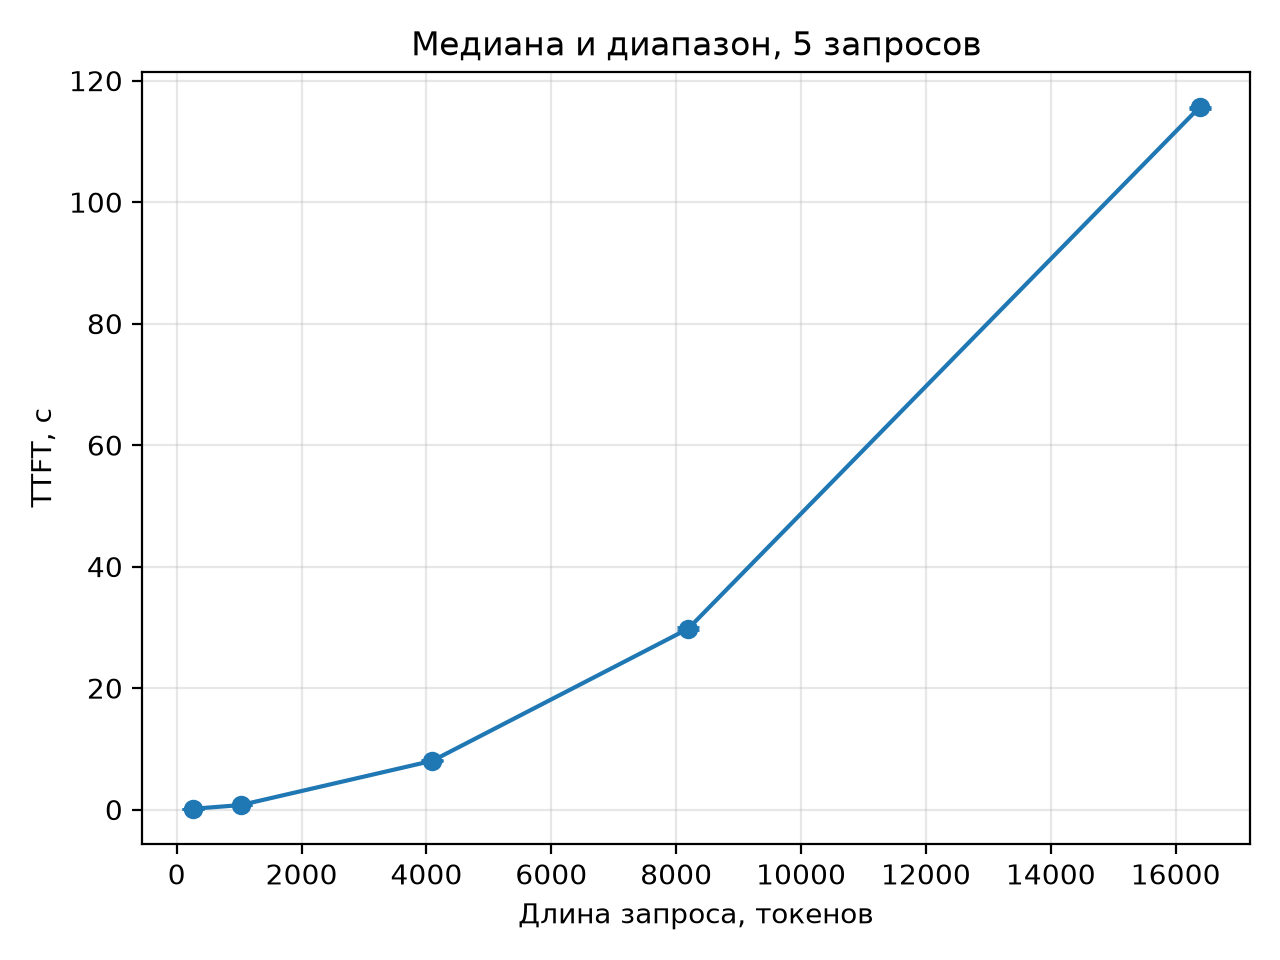

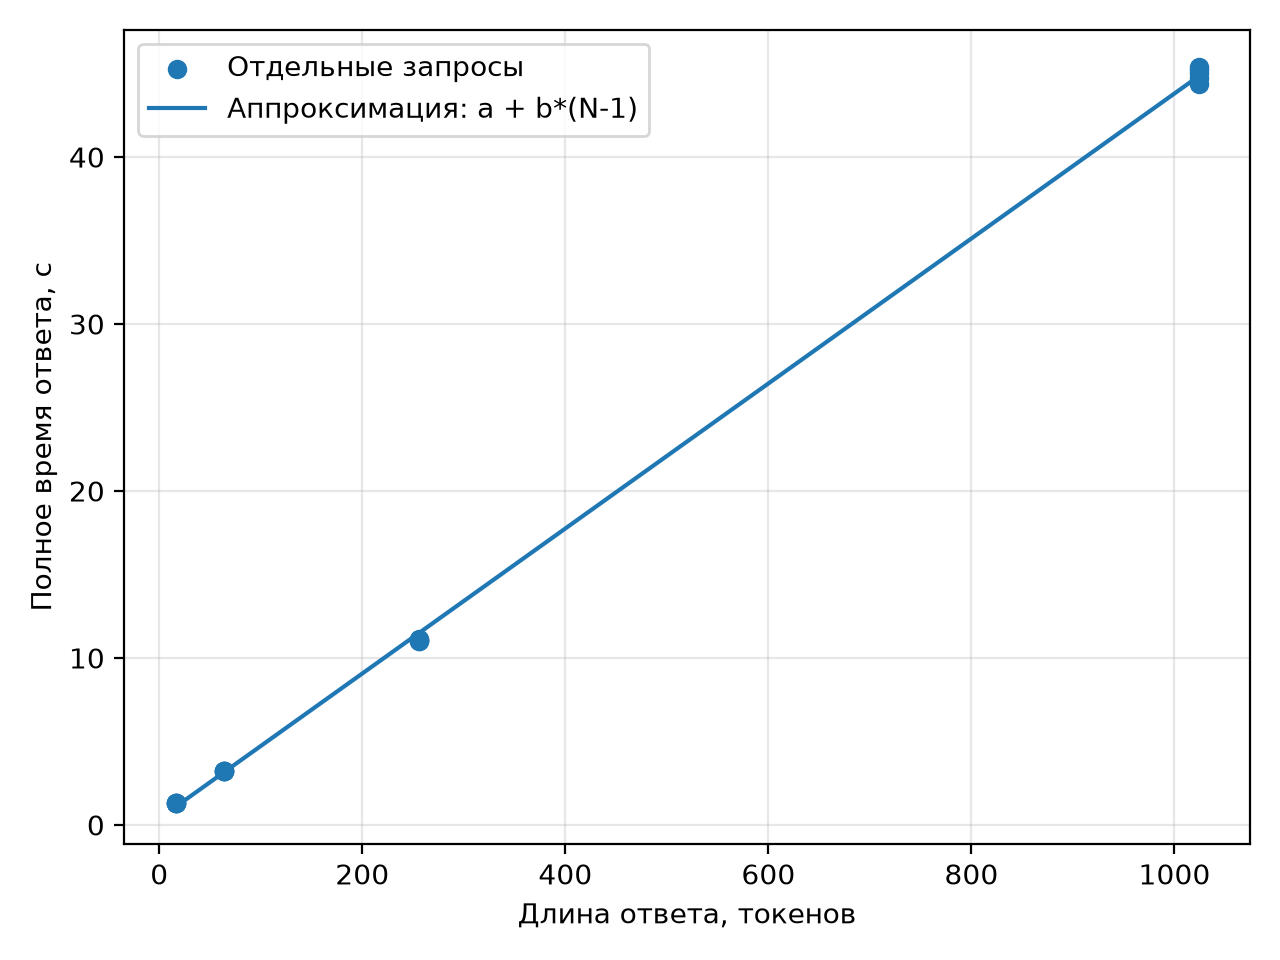

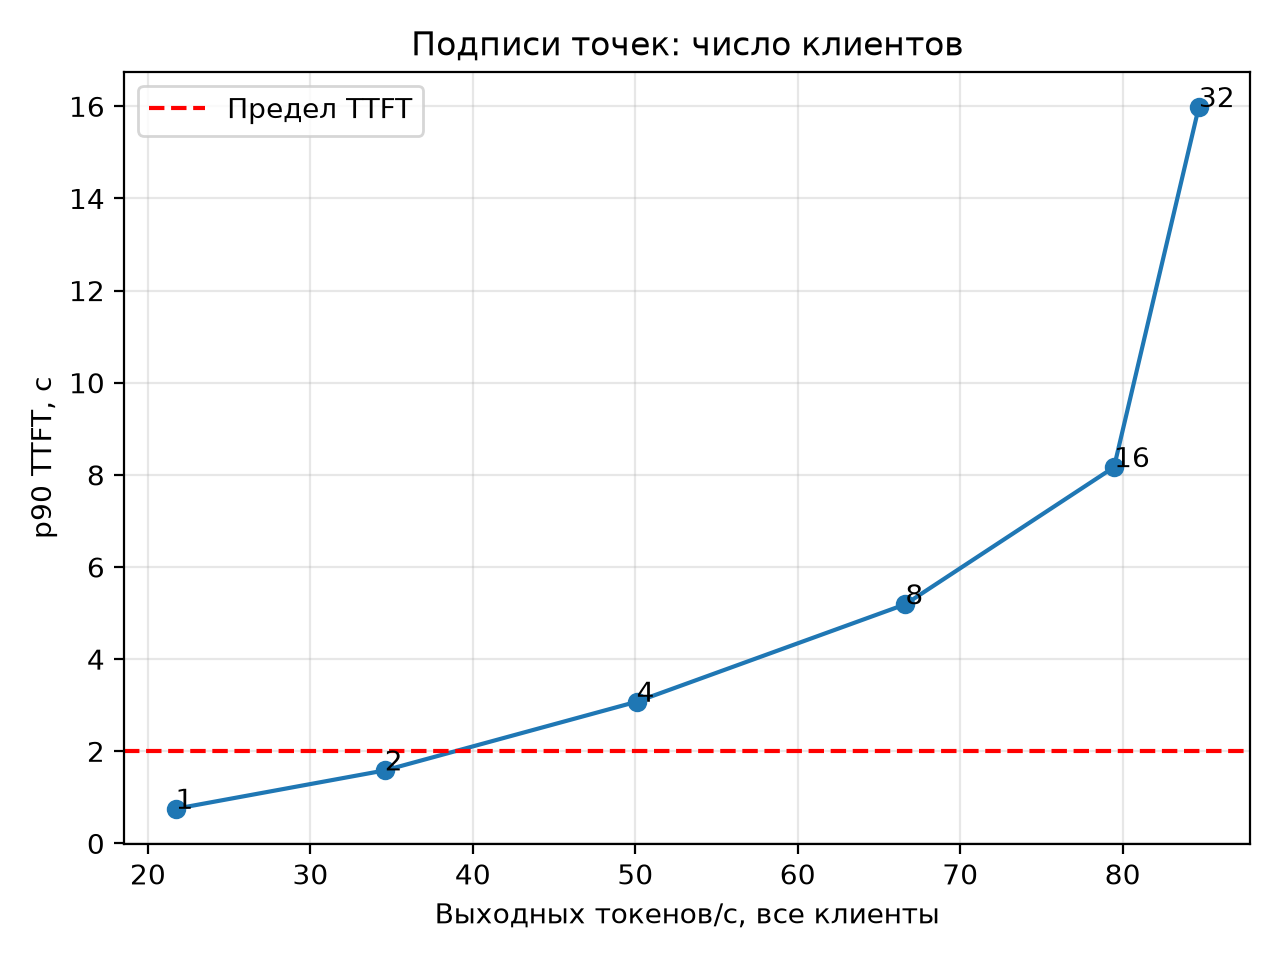

{
  "selected_runs": {
    "check": "7008927a5aa3421e89732827e8105d11",
    "exp1": "59007888fc974d3788b08fe059a1e344",
    "cache": "9ea743be04024a6ab9f6b8814e4da96d",
    "exp2": "580254fb4e534eafbc2a0d5a0356e562",
    "exp3": "ac525836da0c422191b5e9b8ac2056bf"
  },
  "cache_ttft_s": [
    29.253131114999633,
    0.2212622540000666,
    0.21453847700013284
  ],
  "cache_speedup_second": 132.2102192585945,
  "cache_speedup_third": 136.35377450256402,
  "max_concurrency_meeting_limits": 2,
  "note": "0 означает: ни один проверенный уровень не выполнил оба условия",
  "fit": {
    "intercept_s": 0.4274987528488539,
    "slope_s_per_token": 0.043421556432894255,
    "formula": "e2e_s = intercept_s + slope_s_per_token * (N - 1)",
    "rough_t4_4b_fp16_lower_bound_s": 0.02666666666666667,
    "lower_bound_note": "Грубая оценка из методички, не точное время нашей модели"
  }
}



In [19]:
from IPython.display import display, Image

latest = json.loads(
    (ART / "latest_analysis.json").read_text(encoding="utf-8")
)
analysis_dir = ART / "analysis" / latest["analysis_id"]

for name in ["exp1_ttft.png", "exp2_time.png", "exp3_load.png"]:
    display(Image(filename=str(analysis_dir / name)))

print(
    (analysis_dir / "summary.json").read_text(encoding="utf-8")
)